<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介


### 1.1 公司简介
**中国恒大集团**（China Evergrande Group，03333.HK，于开曼群岛注册、香港上市），1996 年由许家印在广州创立，主营住宅房地产开发与销售，并延伸至商业地产、文旅、健康、新能源汽车等多元业务。曾多年跻身全国房企销售第一梯队。

- **上市**：2009 年 11 月 5 日在香港联交所主板挂牌（股份代号 03333）。
- **高光时刻**：2016 年公司规模快速扩张（当年合约销售额超 3700 亿元、居房企首位），2016 年首次入选《财富》世界 500 强；2020 年合约销售额约 7232 亿元。
- **爆雷与破产（清盘）时间线**（本作业所研究"爆雷、破产前十年"指 2011—2021 年）：

| 时间 | 事件 |
|---|---|
| 2009-11-05 | 于港交所挂牌上市，募资约 56 亿港元 |
| 2015—2017 | 高杠杆高周转扩张，中期净负债率一度高达 240%（2017 年中） |
| 2021-09 | 恒大财富理财产品兑付危机爆发，债务风险公开化 |
| 2021-12 | 境外美元债利息兑付逾期，正式构成债务违约 |
| 2022-03-21 | 股份停止买卖（停牌） |
| 2023-07 | 补发 2021、2022 年年报：2021 年亏损 6862.2 亿元（归母 -4760.35 亿元）、2022 年亏损 1258.14 亿元，两年合计巨亏约 8120 亿元；2021 年末净资产转负（-4730 亿元），资不抵债 |
| 2024-01-29 | 香港高等法院颁布清盘令（HCCW 220/2022），委任安迈顾问杜艾迪、黄咏诗为联合清盘人 |
| 2025-08-25 | 港交所取消其上市地位（正式退市/除牌） |

> **数据口径说明**：恒大地産自身为港股且已退市，tushare 不提供其财务报表，故本作业将恒大历年公开年报/港交所披露、中商产业研究院数据库（s.askci.com）、21世纪经济报道等来源的关键财务数据整理为表内数据（单位：人民币亿元）；对照组 A 股房企的 2012—2021 年年度财务报表则由 tushare 实时获取。


# 第二部分：研究问题题目及其内涵介绍


研究题目：**恒大地産在 2021 年债务爆雷、2024 年破产清盘（2025 年退市）之前的十年（2011—2021 年）中，其财务报表展示出了哪些风险迹象？**

内涵介绍与意义：

1. **识别"暴雷征兆"**：通过分析恒大上市后至爆雷前十年的资产负债率、短期偿债能力、盈利能力与经营现金流等指标走向，找出在危机正式爆发前、财务报表中已经显现但一度被忽视的预警信号；
2. **对照验证**：将恒大各项指标与 A 股同类房企对比——其中激进房企（阳光城、华夏幸福、泰禾集团、蓝光发展，后续陆续爆发债务危机）与稳健房企（万科A、保利发展、招商蛇口、金地集团），检验"高杠杆 + 低现金短债比 + 弱现金流"是否为行业性爆雷共性；
3. **现实意义**：为投资者、分析师与监管者提供以财务报表为工具的信用风险早期识别框架，说明央行、住建部 2020 年推出的房企"三条红线"之所以具有预警价值，正是因为它直击报表杠杆与短期偿债两项核心指标。


# 第三部分：数据采集

In [1]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [2]:
# -*- coding: utf-8 -*-
# ============================================================
# 第三部分：数据采集
# 研究主题：恒大地産爆雷（2021）破产清盘（2024）前十年（2011-2021）
#           财务报表中所展示的风险迹象
# 数据说明：
#   1) 中国恒大（03333.HK，2025-08-25 已从港交所除牌）不在 tushare 覆盖范围，
#      tushare 亦不提供港股财务报表。故将恒大历年公开披露的核心财务指标整理为
#      数据表嵌入本部分（来源：中国恒大年报/港交所披露/中商产业研究院/21世纪经济报道等）。
#   2) 用 tushare 采集 A 股主要房企 2012-2021 年年报（利润表/资产负债表/现金流量表），
#      分为“激进房企（后爆雷）”与“稳健房企”两组，观察行业层面爆雷前共性迹象。
# ============================================================
import pandas as pd
import numpy as np
import tushare as ts

pro = ts.pro_api()

# ---------- 1) 恒大地産 2011-2021 关键财务数据（单位：亿元）----------
evg = pd.DataFrame({
    "年份": [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021],
    "营业收入": [619.18, 652.61, 936.72, 1113.98, 1331.30, 2114.44, 3110.22,
                   4661.96, 4775.61, 5072.48, 2500.13],
    "毛利":     [206.08, 182.10, 276.49, 317.84, 374.13, 594.22, 1122.62,
                   1689.47, 1329.37, 1235.04, -184.48],
    "归母净利润": [113.24, 91.71, 126.12, 126.04, 104.60, 50.91, 243.72,
                   373.90, 172.80, 80.76, -4760.35],
    "总资产": [1790.23, 2389.91, 3481.48, 4744.62, 7570.35, 13508.68,
               17617.52, 18800.28, 22065.77, 23011.59, 21070.96],
    "总负债": [1448.93, 1972.99, 2688.06, 3620.84, 6148.93, 11583.36,
               15195.44, 15714.02, 18480.40, 19507.28, 25801.50],
    "净资产": [341.31, 416.91, 793.43, 1123.78, 1421.42, 1925.32, 2422.08,
               3086.26, 3585.37, 3504.31, -4730.54],
    "流动比率": [1.54, 1.33, 1.54, 1.43, 1.34, 1.52, 1.40, 1.36, 1.37, 1.26, 0.75],
    "速动比率": [0.54, 0.35, 0.56, 0.51, 0.50, 0.62, 0.52, 0.42, 0.38, 0.33, 0.17],
})
evg["资产负债率"] = evg["总负债"] / evg["总资产"]
evg["毛利率"] = evg["毛利"] / evg["营业收入"]
evg["净利率"] = evg["归母净利润"] / evg["营业收入"]
evg.to_csv("evergrande_financial.csv", index=False, encoding="utf-8-sig")
print("[OK] 恒大地産 2011-2021 财务数据已保存 (evergrande_financial.csv)")

# 恒大“三条红线”指标（监管红线：资产负债率≤70%；净负债率≤100%；现金短债比≥1）
redlines = pd.DataFrame({
    "指标": ["剔除预收后资产负债率", "净负债率", "现金短债比"],
    "2020年报": [0.83, 1.59, 0.78],
    "2021年报": [0.81, 1.529, 0.47],
    "监管红线": [0.70, 1.00, 1.00],
})
redlines.to_csv("evergrande_redlines.csv", index=False, encoding="utf-8-sig")
print("[OK] 恒大三条红线（2020/2021）已保存 (evergrande_redlines.csv)")

# ---------- 2) tushare：A股对照房企年度财务（2012-2021）----------
aggressive = {"阳光城": "000671.SZ", "华夏幸福": "600340.SH",
              "泰禾集团": "000732.SZ", "蓝光发展": "600466.SH"}
stable = {"万科A": "000002.SZ", "保利发展": "600048.SH",
          "招商蛇口": "001979.SZ", "金地集团": "600383.SH"}

PER_ST, PER_END = "20130101", "20221231"
rows = []
for group, mp in [("激进房企", aggressive), ("稳健房企", stable)]:
    for nm, code in mp.items():
        try:
            inc = pro.income(ts_code=code, start_date=PER_ST, end_date=PER_END)
            bs = pro.balancesheet(ts_code=code, start_date=PER_ST, end_date=PER_END)
            cf = pro.cashflow(ts_code=code, start_date=PER_ST, end_date=PER_END)
        except Exception as e:
            print(f"[警告] {nm}({code}) 获取失败：{str(e)[:80]}")
            continue
        if any(d is None or d.empty for d in (inc, bs, cf)):
            print(f"[警告] {nm}({code}) 数据为空")
            continue
        inc = inc[(inc["report_type"] == "1") & (inc["end_date"].str.endswith("1231"))]
        bs = bs[(bs["report_type"] == "1") & (bs["end_date"].str.endswith("1231"))]
        cf = cf[(cf["report_type"] == "1") & (cf["end_date"].str.endswith("1231"))]
        inc = inc.drop_duplicates("end_date").set_index("end_date")
        bs = bs.drop_duplicates("end_date").set_index("end_date")
        cf = cf.drop_duplicates("end_date").set_index("end_date")
        common = inc.index.intersection(bs.index).intersection(cf.index)
        for d in common:
            year = int(d[:4])
            if not (2012 <= year <= 2021):
                continue
            ta = bs.loc[d, "total_assets"]
            tl = bs.loc[d, "total_liab"]
            mc = bs.loc[d, "money_cap"] if "money_cap" in bs.columns else np.nan
            sb = bs.loc[d, "st_borr"] if "st_borr" in bs.columns else np.nan
            nd = bs.loc[d, "non_cur_liab_due_1y"] if "non_cur_liab_due_1y" in bs.columns else np.nan
            rev = inc.loc[d, "total_revenue"]
            ni = inc.loc[d, "n_income"]
            ocf = cf.loc[d, "n_cashflow_act"] if "n_cashflow_act" in cf.columns else np.nan
            rows.append({
                "group": group, "公司": nm, "code": code, "year": year,
                "资产负债率": tl / ta,
                "现金短债比": mc / (sb + nd) if pd.notna(sb) and pd.notna(nd) and (sb + nd) else np.nan,
                "经营现金流/净利润": ocf / ni if pd.notna(ni) and ni else np.nan,
            })
        print(f"[OK] {nm}({code}) 整理完成")

proxy = pd.DataFrame(rows)
proxy.to_csv("proxy_financial.csv", index=False, encoding="utf-8-sig")
print("对照房企数据条数：", len(proxy))

# 分组逐年均值
avg = proxy.groupby(["group", "year"])[["资产负债率", "现金短债比", "经营现金流/净利润"]].mean().reset_index()
avg.to_csv("proxy_financial_avg.csv", index=False, encoding="utf-8-sig")
print(avg.pivot_table(index="year", columns="group", values="资产负债率").to_string())

print("\n数据采集完成：")
print("  evergrande_financial.csv    - 恒大地産 2011-2021 财务（年报整理）")
print("  evergrande_redlines.csv     - 恒大三条红线指标")
print("  proxy_financial.csv         - A股对照房企年度财务（tushare）")
print("  proxy_financial_avg.csv     - 对照组逐年均值")

[OK] 恒大地産 2011-2021 财务数据已保存 (evergrande_financial.csv)
[OK] 恒大三条红线（2020/2021）已保存 (evergrande_redlines.csv)


[OK] 阳光城(000671.SZ) 整理完成


[OK] 华夏幸福(600340.SH) 整理完成


[OK] 泰禾集团(000732.SZ) 整理完成


[OK] 蓝光发展(600466.SH) 整理完成


[OK] 万科A(000002.SZ) 整理完成


[OK] 保利发展(600048.SH) 整理完成


[OK] 招商蛇口(001979.SZ) 整理完成


[OK] 金地集团(600383.SH) 整理完成
对照房企数据条数： 80
group      激进房企      稳健房企
year                     
2012   0.649749  0.750177
2013   0.678405  0.747496
2014   0.695704  0.739027
2015   0.812258  0.725001
2016   0.830920  0.724241
2017   0.836499  0.763737
2018   0.849989  0.782374
2019   0.832325  0.751833
2020   0.843137  0.755481
2021   0.930245  0.754915

数据采集完成：
  evergrande_financial.csv    - 恒大地産 2011-2021 财务（年报整理）
  evergrande_redlines.csv     - 恒大三条红线指标
  proxy_financial.csv         - A股对照房企年度财务（tushare）
  proxy_financial_avg.csv     - 对照组逐年均值


# 第四部分：数据分析过程

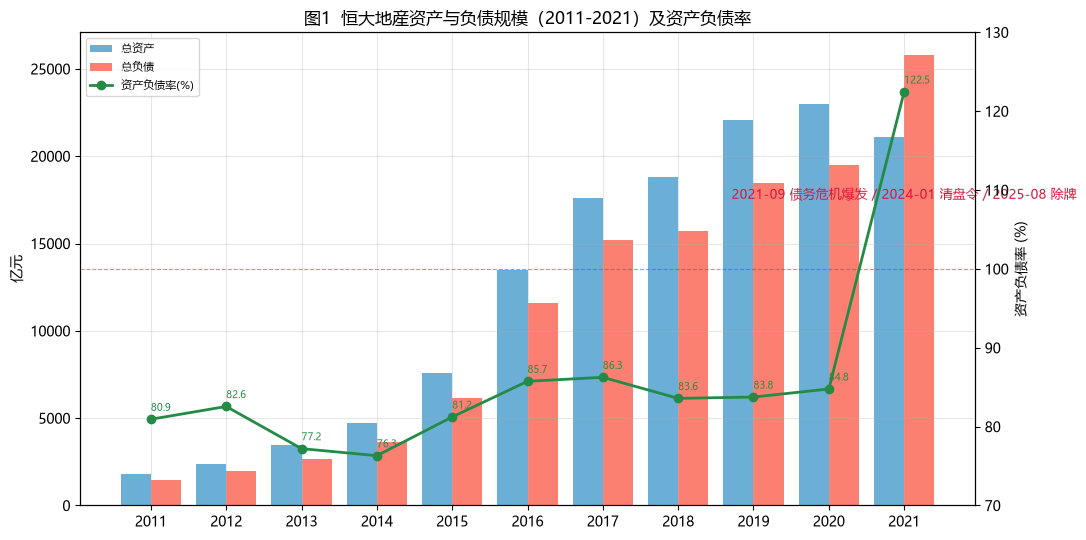

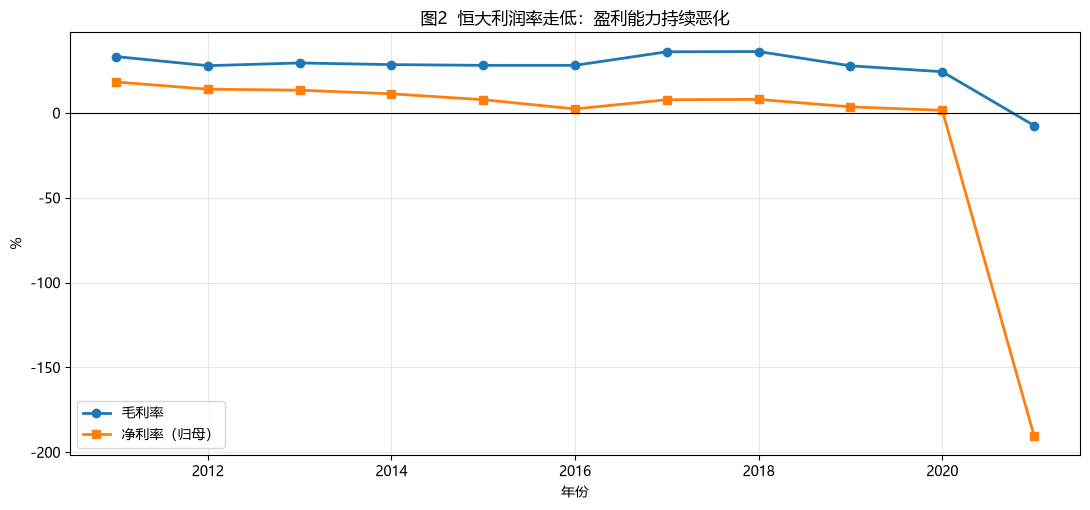

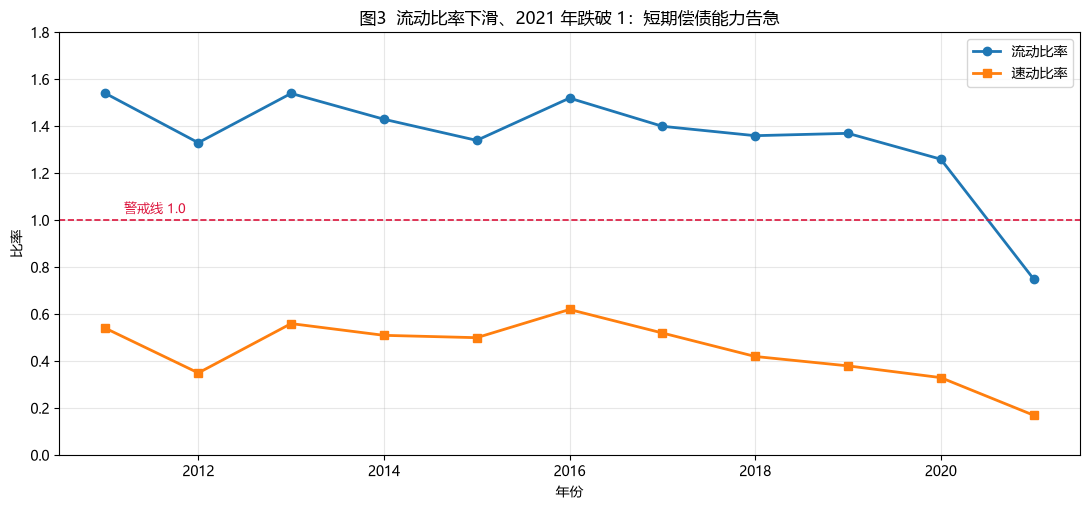

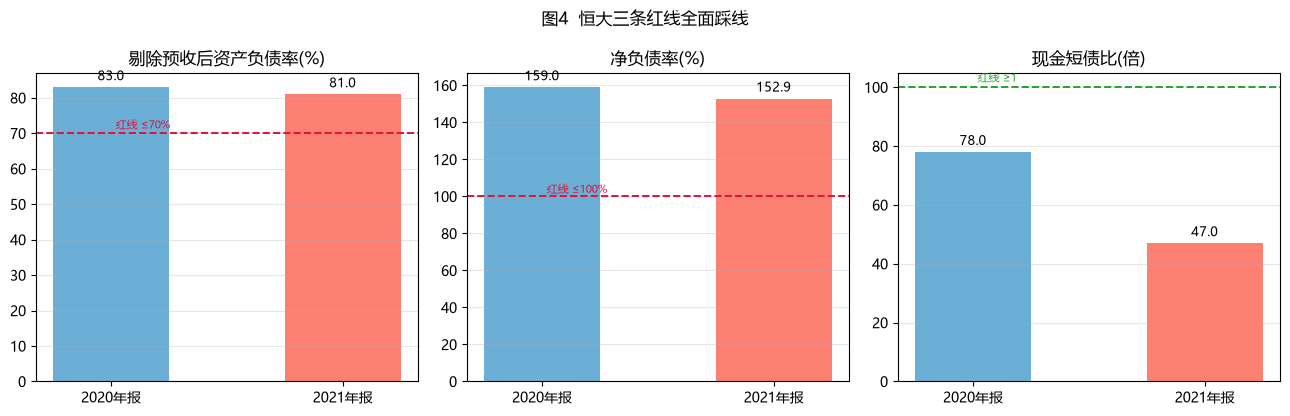

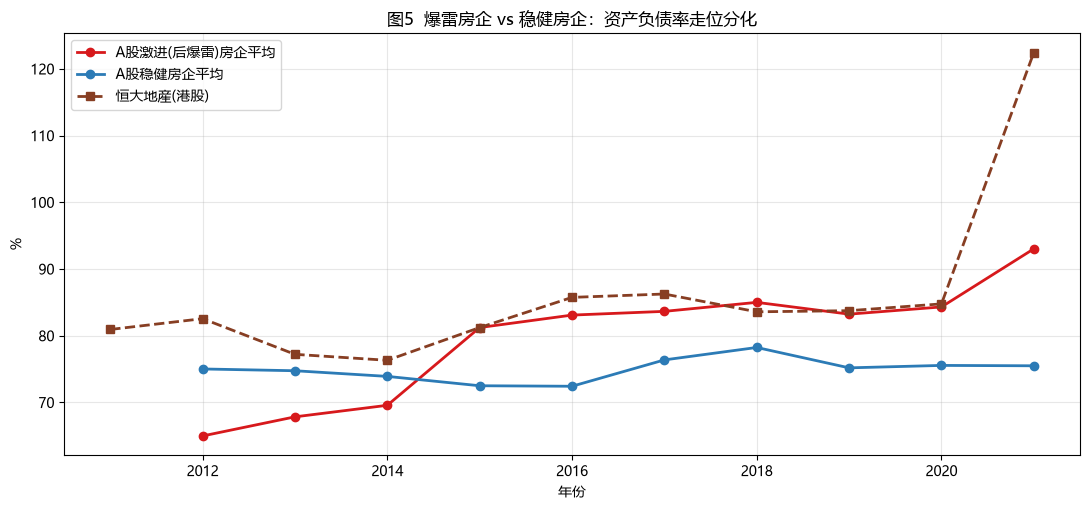

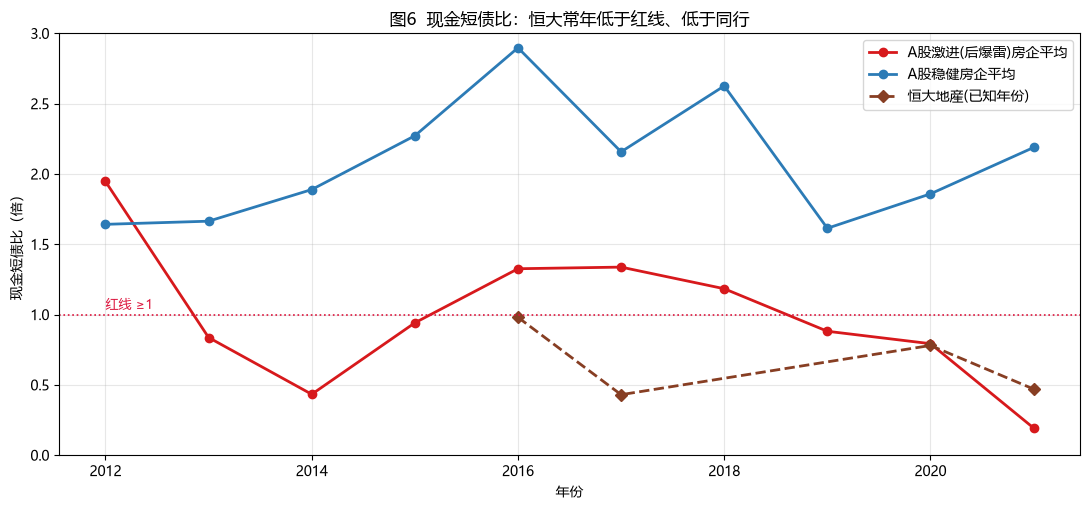

A股对照组关键指标均值（2012-2021）：
       资产负债率  现金短债比  经营现金流/净利润
group                         
激进房企   0.796  0.980     -0.513
稳健房企   0.749  2.081      0.541

恒大地産陷落前后（亿元）：
  年份    营业收入    归母净利润      总资产      总负债      净资产
2019 4775.61   172.80 22065.77 18480.40  3585.37
2020 5072.48    80.76 23011.59 19507.28  3504.31
2021 2500.13 -4760.35 21070.96 25801.50 -4730.54


In [2]:
# -*- coding: utf-8 -*-
# ============================================================
# 第四部分：数据分析与可视化
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
rcParams["axes.unicode_minus"] = False

evg = pd.read_csv("evergrande_financial.csv")
red = pd.read_csv("evergrande_redlines.csv")
avg = pd.read_csv("proxy_financial_avg.csv")
proxy = pd.read_csv("proxy_financial.csv")

YEARS = evg["年份"]
LBL = "2021-09 债务危机爆发 / 2024-01 清盘令 / 2025-08 除牌"

# ---------- 图1：资产/负债规模膨胀 + 资产负债率 ----------
fig, ax = plt.subplots(figsize=(11, 5.5))
w = 0.4
ax.bar(YEARS - 0.2, evg["总资产"], w, label="总资产", color="#6baed6")
ax.bar(YEARS + 0.2, evg["总负债"], w, label="总负债", color="#fb8072")
ax.set_ylabel("亿元")
ax.set_title("图1  恒大地産资产与负债规模（2011-2021）及资产负债率")
plt.xticks(YEARS)
ax2 = ax.twinx()
ax2.plot(YEARS, evg["资产负债率"] * 100, "-o", color="#238b45", lw=2, label="资产负债率(%)")
ax2.set_ylim(70, 130)
ax2.axhline(100, color="#238b45", ls="--", lw=0.8, alpha=0.6)
ax2.set_ylabel("资产负债率 (%)")
for i, v in enumerate(evg["资产负债率"] * 100):
    ax2.annotate(f"{v:.1f}", (YEARS[i], v), textcoords="offset points",
                 xytext=(0, 6), fontsize=7, color="#238b45")
ax.annotate(LBL, xy=(2021, evg.loc[9, "总负债"] * 0.9), fontsize=9, color="crimson",
            ha="center")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig1_evg_leverage.png", dpi=130); plt.show()

# ---------- 图2：毛利率 / 净利率（盈利能力）----------
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(YEARS, evg["毛利率"] * 100, "-o", label="毛利率", lw=2)
ax.plot(YEARS, evg["净利率"] * 100, "-s", label="净利率（归母）", lw=2)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("图2  恒大利润率走低：盈利能力持续恶化")
ax.set_ylabel("%"); ax.set_xlabel("年份")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig2_evg_profit.png", dpi=130); plt.show()

# ---------- 图3：流动比率 / 速动比率（短期偿债）----------
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(YEARS, evg["流动比率"], "-o", label="流动比率", lw=2)
ax.plot(YEARS, evg["速动比率"], "-s", label="速动比率", lw=2)
ax.axhline(1.0, color="crimson", ls="--", lw=1.2)
ax.text(2011.2, 1.03, "警戒线 1.0", color="crimson", fontsize=9)
ax.set_ylim(0, 1.8)
ax.set_title("图3  流动比率下滑、2021 年跌破 1：短期偿债能力告急")
ax.set_ylabel("比率"); ax.set_xlabel("年份")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig3_evg_liquidity.png", dpi=130); plt.show()

# ---------- 图4：三条红线（2020 vs 2021 vs 监管红线）----------
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
specs = [("剔除预收后资产负债率(%)", 0.70, "≤70%", "crimson"),
         ("净负债率(%)", 1.00, "≤100%", "crimson"),
         ("现金短债比(倍)", 1.00, "≥1", "#2ca02c")]
for ax, (name, th, tag, col) in zip(axes, specs):
    v20 = red.loc[red["指标"] == name.split("(")[0], "2020年报"].values[0] * 100
    v21 = red.loc[red["指标"] == name.split("(")[0], "2021年报"].values[0] * 100
    ax.bar([0, 1], [v20, v21], width=0.5, color=["#6baed6", "#fb8072"])
    ax.axhline(th * 100, color=col, ls="--", lw=1.4)
    ax.text(0.02, th * 100 * 1.02, f"红线 {tag}", color=col, fontsize=8)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["2020年报", "2021年报"])
    ax.set_title(name)
    for j, v in enumerate([v20, v21]):
        ax.annotate(f"{v:.1f}", (j, v), textcoords="offset points",
                    xytext=(0, 5), ha="center", fontsize=9)
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("图4  恒大三条红线全面踩线", fontsize=12)
fig.tight_layout(); fig.savefig("fig4_evg_redlines.png", dpi=130); plt.show()

# ---------- 图5：对照组资产负债率均值 vs 恒大 ----------
fig, ax = plt.subplots(figsize=(11, 5.2))
for g, c in [("激进房企", "#d7191c"), ("稳健房企", "#2c7bb6")]:
    sub = avg[avg["group"] == g]
    nm = "A股激进(后爆雷)房企平均" if g == "激进房企" else "A股稳健房企平均"
    ax.plot(sub["year"], sub["资产负债率"] * 100, "-o", label=nm, color=c, lw=2)
ax.plot(YEARS, evg["资产负债率"] * 100, "--s", label="恒大地産(港股)", lw=2, color="#873e23")
ax.set_title("图5  爆雷房企 vs 稳健房企：资产负债率走位分化")
ax.set_ylabel("%"); ax.set_xlabel("年份")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig5_cmp_debtratio.png", dpi=130); plt.show()

# ---------- 图6：现金短债比 对照组 vs 恒大 ----------
cash_known = pd.DataFrame({"年份": [2016, 2017, 2020, 2021],
                           "值": [0.98, 0.43, 0.78, 0.47]})
fig, ax = plt.subplots(figsize=(11, 5.2))
for g, c in [("激进房企", "#d7191c"), ("稳健房企", "#2c7bb6")]:
    sub = avg[avg["group"] == g]
    nm = "A股激进(后爆雷)房企平均" if g == "激进房企" else "A股稳健房企平均"
    ax.plot(sub["year"], sub["现金短债比"], "-o", label=nm, color=c, lw=2)
ax.plot(cash_known["年份"], cash_known["值"], "D--", color="#873e23", lw=2,
        label="恒大地産(已知年份)")
ax.axhline(1.0, color="crimson", ls=":", lw=1.2)
ax.text(2012, 1.04, "红线 ≥1", color="crimson", fontsize=9)
ax.set_ylim(0, 3.0)
ax.set_title("图6  现金短债比：恒大常年低于红线、低于同行")
ax.set_ylabel("现金短债比（倍）"); ax.set_xlabel("年份")
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("fig6_cmp_cash.png", dpi=130); plt.show()

# ---------- 汇总表：爆雷前后对照均值 ----------
print("A股对照组关键指标均值（2012-2021）：")
print(proxy.groupby("group")[["资产负债率", "现金短债比", "经营现金流/净利润"]]
      .mean().round(3).to_string())
print("\n恒大地産陷落前后（亿元）：")
print(evg[["年份", "营业收入", "归母净利润", "总资产", "总负债", "净资产"]]
      .query("年份 in [2019, 2020, 2021]").round(2).to_string(index=False))

# 第五部分：研究结论与经验总结


## 研究结论

1. **高杠杆是爆雷的底色**：恒大地産总资产由 2011 年 1790 亿元膨胀至 2020 年峰值 23012 亿元，总负债则由 1449 亿元增至 2021 年 25802 亿元（约 2011 年的 17.8 倍）；资产负债率从 2011 年 80.9% 升至 2017 年 86.3%，2021 年因巨额亏损、净资产转负（-4731 亿元）而达 122.5%，正式资不抵债。
2. **短期偿债能力持续恶化**：流动比率由 2011 年 1.54 降至 2021 年 0.75，速动比率由 0.54 降至 0.17，2020 年后双双跌破 1；现金短债比已知年份 2016 年 0.98→2017 年 0.43→2020 年 0.78→2021 年 0.47，长期低于监管要求的 ≥1。
3. **盈利质量先于危机下滑**：毛利率由 2011 年 33.3% 降至 2020 年 24.3%（2021 年转负 -7.4%），净利率 2019 年 3.6%→2020 年 1.6%→2021 年暴跌至 -190.4%，出现"增收不增利、利润率持续下台阶"。
4. **对照组验证爆雷共性**：tushare 数据显示 A 股激进房企平均资产负债率由 2012 年 65.0% 一路升至 2021 年 93.0%（十年均值 79.6%），稳健房企则稳定在 72.5%—78.2%（均值 74.9%）；激进组十年现金短债比均值 0.98、经营现金流/净利润 -0.51，稳健组为 2.08 与 +0.54。恒大地産正落在这场分化中"激进、危险"的显著一端。
5. **"三条红线"具备预警价值**：恒大 2020/2021 年剔除预收后资产负债率 83%/81%（红线 ≤70%）、净负债率 159%/152.9%（红线 ≤100%）、现金短债比 0.78/0.47（红线 ≥1.0），三项指标全面踩线——说明监管 2020 年提出的三条红线正是基于这些报表指标早于爆雷给出的信号。



> **图表与数据文件**：本作业共生成 6 张图（fig1_evg_leverage / fig2_evg_profit / fig3_evg_liquidity / fig4_evg_redlines / fig5_cmp_debtratio / fig6_cmp_cash）与 4 个数据文件（evergrande_financial.csv、evergrande_redlines.csv、proxy_financial.csv、proxy_financial_avg.csv），代码可复现。



## 经验总结

- **数据可获得性**：tushare 覆盖 A 股财务报表非常方便，但**不提供港股财务报表**，且已退市港股（03333.HK）不在其港股列表中。对港股/退市公司应采用"已有公开数据整理内嵌 + 同行业 A 股对照"的办法，并明确数据口径与来源，避免造数。
- **财务分析的"预警四看"**：一看杠杆（资产负债率、净负债率、剔除预收后资产负债率）；二看短期偿债（流动比率、速动比率、现金短债比）；三看盈利质量（毛利率、净利率、经营现金流/净利润）；四看权益结构（少数股东权益被用于"明股实债"式表外融资）。
- **对比法是放大镜**：单看一家公司的绝对数容易麻木，将恒大放入"爆雷组 vs 稳健组"横向对比后，85% 对 75% 的资产负债率、低于 1 的现金短债比，风险一目了然。
- **工具与工程坑**：本项目在 Jupyter（.venv 内核）中由 pandas + matplotlib 完成采集与绘图；注意中文字体设置（Microsoft YaHei，axes.unicode_minus=False）、指标分母为空值的处理（资产负债表无 short_borr 字段，短期借款为 st_borr，一年内到期非流动负债为 non_cur_liab_due_1y）。
- **研究局限**：恒大净负债率、现金短债比等指标仅部分年份有可靠披露值，图中以散点标注；本作业数据来源于公开渠道，指标口径如有差异以公司年报为准。
